<a href="https://colab.research.google.com/github/kpmunoz09/DeepLearning/blob/main/Sanabria_Maria_Munoz_Karen_Sem5_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Taller Casos de uso de los diferentes tipos de arquitectura de deep learning


##### Sanabria María Ximena
##### Muñoz Karen Paola

##Parte A. Implementación de una MLP sobre datos tabulares
#### Elegimos el dataset Iris para el desarrollo de la primera parte de la actividad.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Input

In [ ]:
# 1. Cargamos el dataset Iris
iris = load_iris()
X = iris.data  # Variables de entrada
y = iris.target.reshape(-1, 1)  # Etiquetas

In [ ]:
# 2. División en Entrenamiento y Prueba (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y.ravel())

In [ ]:
# 3. Se normalizan variables del dataset Iris
# La normalización con StandardScaler sirve para transformar las variables numéricas del dataset
# para que tengan una media de 0 y una desviación estándar de 1.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# 4. Codificar etiquetas (One-Hot Encoding para 3 clases)
# En este paso de realiza la codificación de las etiquetas del dataset. Sirve para transformar las categorías numéricas simples
# de las flores Iris (0, 1 y 2) en vectores binarios compatibles con la capa de salida de la red neuronal (ceros y unos).

encoder = OneHotEncoder(sparse_output=False) # devuelve una matriz densa estándar de NumPy (un arreglo común) en lugar de una matriz dispersa.
y_train_encoded = encoder.fit_transform(y_train) # Identifica cuántas clases distintas existen en el conjunto de entrenamiento y las pasa a vectores de 0s y 1s
y_test_encoded = encoder.transform(y_test) # Convierte los valores de y_test al formato de vectores de 0s y 1s.

In [ ]:
# 5. Mostrar dimensiones y ejemplos de datos procesados en los puntos anteriores
print("Dimensiones X_train procesado:", X_train_scaled.shape)
print("Dimensiones y_train codificado:", y_train_encoded.shape)
print("\nEjemplo de datos de entrada procesados (3 filas):")
print(X_train_scaled[:3])
print("\nEjemplo de etiquetas procesadas (3 filas):")
print(y_train_encoded[:3])

Dimensiones X_train procesado: (120, 4)
Dimensiones y_train codificado: (120, 3)

Ejemplo de datos de entrada procesados (3 filas):
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]]

Ejemplo de etiquetas procesadas (3 filas):
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]


In [ ]:
# 1. Definir la arquitectura
# Se crea un modelo secuencial en Keras/TensorFlow.
# Significa que la información fluirá en una sola dirección, pasando secuencialmente de la primera capa a la última.
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),  # En esta capa de entrada le pasamos al modelo la información de X_train_scaled, que tiene los datos de entrada procesados (Largo/ancho de sépalo y pétalo)

    # Capa oculta 1: 16 neuronas, activación ReLU,
    Dense(16, activation='relu'),

    # Capa oculta 2: 8 neuronas, activación ReLU
    # Esta segunda capa ayuda a comprimir y abstraer la información aprendida por la primera capa antes de llegar a la decisión final.
    Dense(8, activation='relu'),

    # Capa de salida: 3 neuronas (para Iris, clasificación multiclase) con Softmax
    # Esta última capa tiene 3 neuronas, una por cada especie de flor Iris (probabilidades: setosa, versicolor, virginica)
    Dense(3, activation='softmax')
])

In [ ]:
# 2. Compilar el modelo
model.compile(
    optimizer='adam', # Justificación: Adam combina AdaGrad y RMSProp, adaptando la tasa de aprendizaje.
    loss='categorical_crossentropy', # Función de pérdida adecuada para etiquetas One-Hot multiclase
    metrics=['accuracy'] # Métrica de evaluación requerida
)

# 3. Resumen del modelo y parámetros
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Entrenamiento del modelo para el dataset Iris
history = model.fit(
    X_train_scaled,
    y_train_encoded,
    epochs=40,
    batch_size=8,
    validation_split=0.2
)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.1771 - loss: 1.1591 - val_accuracy: 0.2917 - val_loss: 1.1263
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.2083 - loss: 1.0635 - val_accuracy: 0.3333 - val_loss: 1.0394
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4271 - loss: 0.9830 - val_accuracy: 0.5417 - val_loss: 0.9844
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6667 - loss: 0.9329 - val_accuracy: 0.6250 - val_loss: 0.9475
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7396 - loss: 0.8878 - val_accuracy: 0.6250 - val_loss: 0.9130
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7604 - loss: 0.8441 - val_accuracy: 0.6250 - val_loss: 0.8757
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7708 - loss: 0.7997 - val_accuracy: 0.6667 - val_loss: 0.8374
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7917 - loss: 0.7528 - val_accuracy: 0.7083 - v

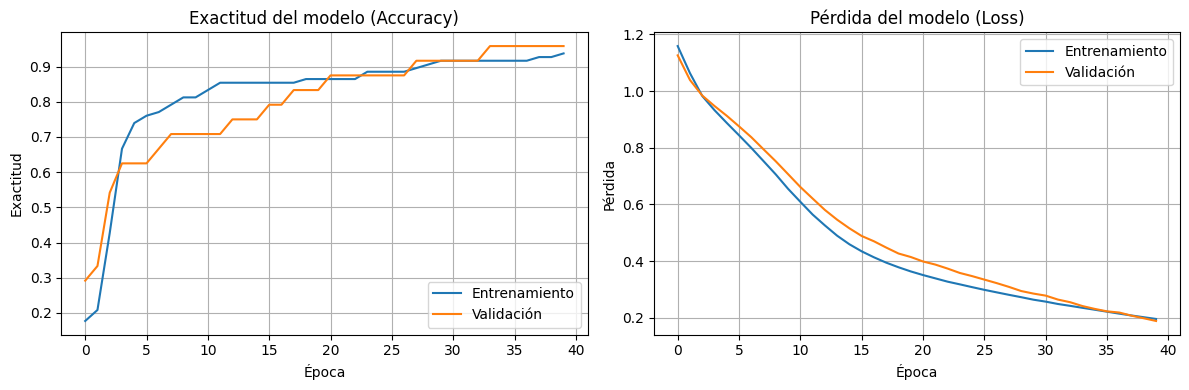

In [ ]:
import matplotlib.pyplot as plt

# Crear la figura con 2 subgráficos (Exactitud y Pérdida)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Exactitud (Accuracy)
ax1.plot(history.history['accuracy'], label='Entrenamiento')
ax1.plot(history.history['val_accuracy'], label='Validación')
ax1.set_title('Exactitud del modelo (Accuracy)')
ax1.set_xlabel('Época')
ax1.set_ylabel('Exactitud')
ax1.legend()
ax1.grid(True)

# Gráfico 2: Pérdida (Loss)
ax2.plot(history.history['loss'], label='Entrenamiento')
ax2.plot(history.history['val_loss'], label='Validación')
ax2.set_title('Pérdida del modelo (Loss)')
ax2.set_xlabel('Época')
ax2.set_ylabel('Pérdida')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Evaluación del modelo con los datos de prueba del dataset Iris
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test_encoded)
print(f"\nPérdida en el conjunto de prueba (Test loss): {test_loss:.4f}")
print(f"Precisión en el conjunto de prueba (Test accuracy): {test_accuracy * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.9333 - loss: 0.2433

Pérdida en el conjunto de prueba (Test loss): 0.2433
Precisión en el conjunto de prueba (Test accuracy): 93.33%


## Parte B. Implementación de una CNN sobre MNIST

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

Dimensiones de entrenamiento: (60000, 28, 28, 1)
Dimensiones de prueba: (10000, 28, 28, 1)


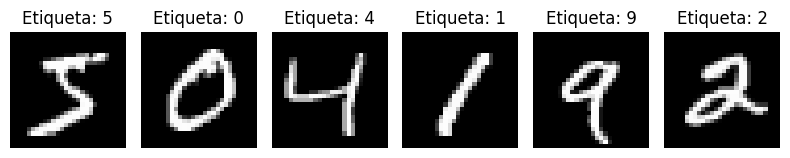

In [ ]:
# 1. Cargamos el conjunto de datos MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# 2. Normalizar píxeles (escalar los valores entre 0 y 1)
# la conversión a flotante evita la división entera en Python que convertiría cualquier valor menor a 255 en 0.
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# 3. Ajuste de dimensiones (reshape)
# Para capas Conv2D en Keras se requiere el formato: (alto, ancho, canales)
# MNIST es en escala de grises, por lo que canales = 1, si fuese en escala de color el valor sería 3.
X_train = X_train.reshape((-1, 28, 28, 1))
X_test = X_test.reshape((-1, 28, 28, 1))

print(f"Dimensiones de entrenamiento: {X_train.shape}")
print(f"Dimensiones de prueba: {X_test.shape}")

# 4. Mostrar ejemplos de imágenes:
plt.figure(figsize=(8, 4))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Etiqueta: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Definimos el modelo CNN:
model = models.Sequential([
    # Usar Input(shape) explícitamente al inicio:
    layers.Input(shape=(28, 28, 1)),

    # Capa convolucional
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)), # Reduce la resolución espacial de la imagen a la mitad
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compilamos el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento deL Modelo:
history = model.fit(
    X_train, y_train,
    epochs=5,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.9393 - loss: 0.2095 - val_accuracy: 0.9758 - val_loss: 0.0864
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 32ms/step - accuracy: 0.9795 - loss: 0.0685 - val_accuracy: 0.9822 - val_loss: 0.0645
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9859 - loss: 0.0460 - val_accuracy: 0.9863 - val_loss: 0.0503
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9896 - loss: 0.0343 - val_accuracy: 0.9865 - val_loss: 0.0482
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9921 - loss: 0.0254 - val_accuracy: 0.9865 - val_loss: 0.0500


**Gráficas**

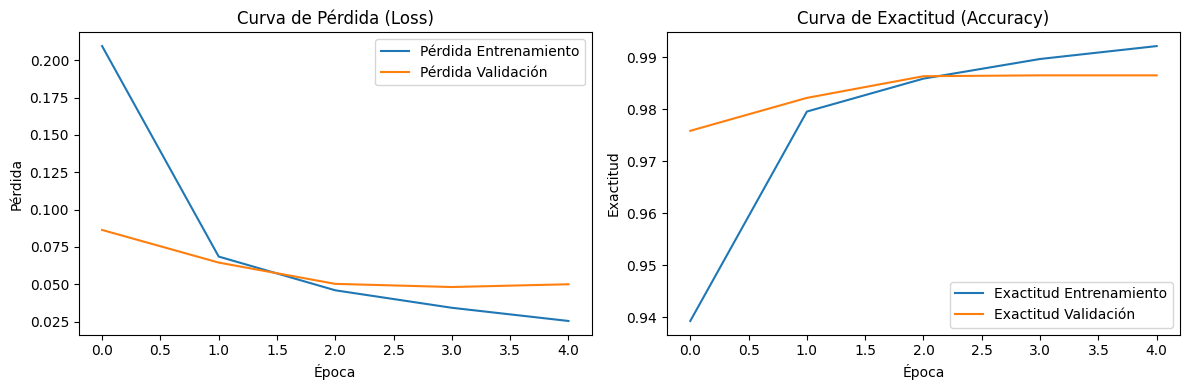

In [ ]:
# Curvas de pérdida y exactitud
plt.figure(figsize=(12, 4))

# Gráfica de Pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.title('Curva de Pérdida (Loss)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

# Gráfica de Exactitud
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Exactitud Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Exactitud Validación')
plt.title('Curva de Exactitud (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluación en el conjunto de prueba (Test)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nResultados en Test:")
print(f"Pérdida (Loss): {test_loss:.4f}")
print(f"Exactitud (Accuracy): {test_acc * 100:.2f}%")



Resultados en Test:
Pérdida (Loss): 0.0542
Exactitud (Accuracy): 98.33%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step


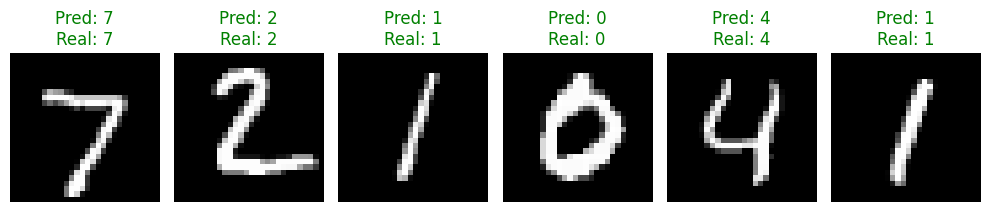

In [ ]:
# Mostrar predicciones reales respecto a predichas
predictions = model.predict(X_test[:6])
pred_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 4))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    color = 'green' if pred_labels[i] == y_test[i] else 'red'
    plt.title(f"Pred: {pred_labels[i]}\nReal: {y_test[i]}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

#Análisis comparativo y justificación técnica (MLP vs CNN)

### **Justificación**:
### Parte A. Implementación de una MLP sobre datos tabulares
##### ● ¿Por qué esta arquitectura es adecuada para este tipo de dato?
###### Para un dataset tabular como el de Iris, la arquitectura MLP es ideal debido a que en el perceptrón multicapa mediante sus capas densas permiten que las variables de entrada se conecten con las neuronas de la siguiente capa, permitiendo así al modelo aprender diversas combinaciones no lineales optimizando el aprendizaje del modelo con la totalidad de los datos.
###### Adicionalmente, el dataset contiene información tabular estructurada de 4 características continuas e independientes (longitud y ancho del sépalo y el pétalo), es decir, en estos datos, las valores no están ordenados ni conectadas entre sí, y tampoco siguen una secuencia en el tiempo.

##### ● ¿Qué ocurriría si usara la otra arquitectura?
###### Si emplearamos una arquitectura CNN para un dataset como Iris generaría una complejidad inecesaria debido a que no existen datos dentro del dataset que se puedan estructurar en grillas como las que opera el modelo.
###### Aplicar operaciones de convolución y pooling sobre un vector de solo 4 columnas tabulares como el del dataset iris, incrementa el costo computacional inútilmente y expone al modelo a un sobreajuste (overfitting) o a la pérdida de patrones globales por un filtrado espacial injustificado.

###### Si bien, si es posible usar una capa convolucional unidimensional en un dataset tabular, esta capa requiere una correlación espacial entre las características, lo cual casi nunca ocurre en ningún conjunto de datos tabulares.

##### ● ¿Qué evidencia empírica respalda su conclusión?
###### La evidencia empírica es el resultado de las **Métricas en prueba** (Test Set): Al evaluar el modelo final en el conjunto de prueba independiente (X_test_scaled), el perceptrón Multicapa alcanzó una precisión del 93.33% y una pérdida de 0.2433.
##### ● ¿Cómo se relaciona la estructura del modelo con el desempeño observado?
###### El modelo cuenta con solo 243 parámetros entrenables. Este diseño ligero se adapta perfectamente al tamaño reducido del dataset (120 muestras de entrenamiento), lo que evita el sobreajuste o memorización de datos, y explica el alto rendimiento obtenido en las pruebas. Estos parámetros entrenables resultan de la estructra del modelo que cuenta con tres capas secuenciales: (Input(4) --> Dense(16, relu) --> Dense(8, relu) --> Dense(3, softmax))

**Referencias:**

*   ¿Qué son las redes neuronales convolucionales? | IBM. (2026, 26 agosto). https://www.ibm.com/mx-es/think/topics/convolutional-neural-networks

*   Villanueva, M. (29 de abril de 2021). Convolutional Neural Networks on Tabular Datasets (Part 1). Medium. https://medium.com/spikelab/convolutional-neural-networks-on-tabular-datasets-part-1-4abdd67795b6





### **Justificación**:
### Parte B. Implementación de una CNN sobre MNIST
##### ● ¿Por qué esta arquitectura es adecuada para este tipo de dato?
###### Para el dataset MNIST, una arquitectura de red convolucional CNN es adecuada debido a que son modelos que pueden reconocer patrones visuales, de forma parecida a cómo lo hace el cerebro humano, además que CNN es un tipo de red neuronal diseñada especialmente para analizar imágenes y otros datos con estructura espacial, como videos o mapas.
###### El modelo implementa una capa Conv2D con filtros de 3 x 3 para mapear patrones visuales (como los bordes) sin perder las relaciones espaciales de la imagen. Complementariamente, se introduce MaxPooling2D para reducir las dimensiones a la mitad; que no solo optimiza el costo computacional, sino que hace al modelo robusto frente a ligeros desplazamientos del dígito.

##### ● ¿Qué ocurriría si usara la otra arquitectura?
###### Si implementaramos una arquitectura MLP tendríamos que aplanar el arreglo bidimensional en un vector unidimensional de 784 valores. Este proceso destruye la relación espacial y la vecindad exietente entre los píxeles. Finalmente, implementar una MLP conllevaría a aumentar el riesgo del sobreajuste y perdida del modelo para poder reconocer los patrones visuales.

##### ● ¿Qué evidencia empírica respalda su conclusión?
###### La evidencia radica en los resultados obtenidos en las métricas que muestran el desempeño en el conjunto de prueba, al evaluar en X_test, el modelo alcanzó un Accuracy del 98.33% y una pérdida de 0.0542 en las 5 épocas de entrenamiento definidas.

##### ● ¿Cómo se relaciona la estructura del modelo con el desempeño observado?
###### La estructura de la CNN está vinculada al alto desempeño observado mediante su diseño en tres etapas que permite al modelo comprender la relación entre los pixeles alcanzando el 98.33% de precisión en prueba sin sobreajustarse:

1.   Extracción y reducción de características (Conv2D + MaxPooling2D): Se retiene la información espacial más relevante y reduciendo la dimensionalidad a la mitad.
2.   Transición a representación vectorial (Flatten) que convierte el mapa de características tridimensional en un vector plano
3.   Clasificación denso-multiclase (softmax): La capa oculta de 64 neuronas integra los rasgos visuales extraídos y la capa final con activación softmax calcula la distribución de probabilidad

**Referencias**

*   Dot CSV. (2020, 12 noviembre). 👁‍🗨 ¡Redes Neuronales CONVOLUCIONALES! ¿Cómo funcionan? [Vídeo]. YouTube. https://www.youtube.com/watch?v=V8j1oENVz00
*   ¿Qué son las redes neuronales convolucionales? | IBM. (2026b, agosto 26). https://www.ibm.com/mx-es/think/topics/convolutional-neural-networks

